In [1]:
import pandas as pd
import numpy as np
import time
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial import distance

In [2]:
similarity_dis = pd.read_csv('cntry_similarity_dis.csv')
similarity_dis.columns =['cntry','dis','simi']

In [3]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [4]:
similarity_dis.head()

,cntry,dis,simi
0,CAN,56,0.994924
1,CAN,51,0.998096
2,CAN,27,0.993867
3,CAN,28,0.994754
4,CAN,19,0.997485


In [5]:
similarity_dis = similarity_dis.merge(stgroup_df, left_on='cntry', right_on='Code')

In [6]:
cntry_level = similarity_dis.groupby(['cntry','ST'])['simi'].mean().reset_index()

In [7]:
cntry_stats = cntry_level.groupby(['ST'])['simi'].agg(['mean','std'])

In [8]:
cntry_stats

,mean,std
ST,,
Advanced,0.981292,0.017628
Developing,0.867702,0.100524
Lagging,0.812557,0.117176
Proficient,0.936504,0.055961


In [8]:
cntry_level.sort_values(by='simi')

,cntry,ST,simi
186,VCT,Lagging,0.171893
42,CYM,Lagging,0.303878
170,TCD,Lagging,0.346677
102,LCA,Lagging,0.488452
174,TKM,Developing,0.564149
...,...,...,...
31,CHE,Advanced,0.989650
8,AUS,Advanced,0.990963
30,CAN,Advanced,0.991587
45,DEU,Advanced,0.991689


/tmp/ipykernel_1427147/3092284767.py:4: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='ST',y='simi',data=cntry_level,ax=ax, order=order, palette=color)


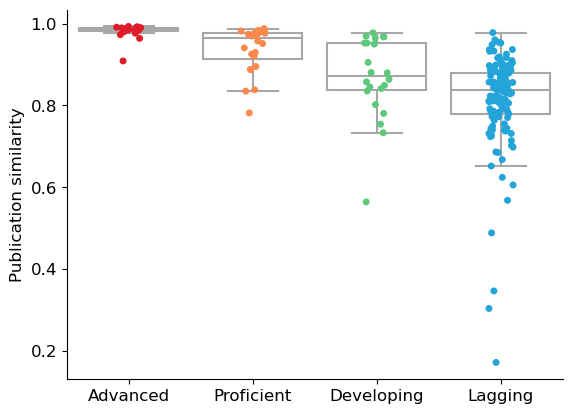

In [37]:
fig, ax=plt.subplots()
color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='simi',data=cntry_level,ax=ax, order=order, palette=color)
sns.boxplot(x='ST',y='simi',data=cntry_level,
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)
ax.set_ylabel("Publication similarity", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig('international_publication_similarity.pdf',bbox_inches='tight')

In [38]:
authorship_data = np.load("similarity_authorship.npz")

In [39]:
ids = authorship_data['ids']
first = authorship_data['inter_f']
last = authorship_data['inter_l']
middle = authorship_data['inter_m']
dome = authorship_data['domestic']

In [40]:
def cal_disimilarity(ids, array1, array2,colname):
    res = []
    for index, id in enumerate(ids):
        vector_1 = array1[index]
        vector_2 = array2[index]
        if not np.all(vector_1==0) and not np.all(vector_2==0) and not np.isnan(np.sum(vector_1)) and not np.isnan(np.sum(vector_2)):
            similarity = 1-distance.cosine(vector_1, vector_2)
            res.append([id[0],id[1],similarity])
    res = pd.DataFrame(res, columns=['cntry','dis',colname])
    return res

In [41]:
first_dome = cal_disimilarity(ids, first, dome, 'first')
middle_dome = cal_disimilarity(ids, middle, dome, 'middle')
last_dome = cal_disimilarity(ids, last, dome, 'last')

In [42]:
meta = first_dome.merge(middle_dome, on=['cntry','dis'])
meta = meta.merge(last_dome, on=['cntry','dis'])
meta = meta.melt(id_vars=['cntry','dis'], var_name=['authorship'],value_name='similarity')

In [44]:
meta = meta.groupby(by=['cntry','authorship'])['similarity'].mean().reset_index()

In [45]:
meta = meta.merge(stgroup_df, left_on='cntry', right_on='Code')

In [47]:
meta.head()

,cntry,authorship,similarity,Code,ST
0,AFG,first,0.881376,AFG,Lagging
1,AFG,last,0.885347,AFG,Lagging
2,AFG,middle,0.904376,AFG,Lagging
3,AGO,first,0.878869,AGO,Lagging
4,AGO,last,0.901820,AGO,Lagging


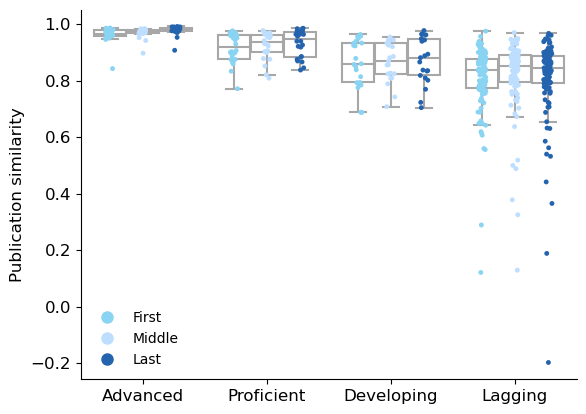

In [65]:
color={'last':'#2464AF','middle':'#BDDEFF','first':'#88D4F2'}
fig, ax = plt.subplots()
sns.stripplot(x='ST',y='similarity', hue='authorship',
              hue_order=['first','middle','last'],
              order=order,
              palette=color,
              data=meta,
              dodge=True,
              ax=ax,
             alpha=1,
              size=3.5)
sns.boxplot(x='ST',y='similarity', hue='authorship',
           hue_order=['first','middle','last'],
           order=order,
           dodge=True,
           data=meta,
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            fliersize=0,
            ax=ax)
legend_handles = [plt.Line2D([], [], color='#88D4F2', marker='o', linestyle='None', markersize=8),
                  plt.Line2D([], [], color='#BDDEFF', marker='o', linestyle='None', markersize=8),
                  plt.Line2D([], [], color='#2464AF', marker='o', linestyle='None', markersize=8)]
plt.legend(legend_handles, ['First','Middle','Last'],loc='lower left', frameon=False)

ax.set_ylabel("Publication similarity", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig('authorship_publication_similarity.pdf',bbox_inches='tight')